# NextGrade AI — Student Performance Prediction
## Exploratory Data Analysis & Machine Learning Modeling Workflow
**Internship Task 2**: Student Performance Prediction  
**Dataset**: UCI Machine Learning Repository — Cortez and Silva (2008)  
**Target Outcomes**: Final Grade $G3 \in [0, 20]$ and Pass/Fail Classification ($G3 \ge 10$)

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import Ridge, LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.metrics import mean_squared_error, r2_score, f1_score, roc_auc_score

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

### 1. Data Ingestion & Preprocessing
Load cleaned and merged student performance data (math + Portuguese, 1,044 observations).

In [2]:
processed_csv = os.path.abspath(os.path.join("..", "..", "data", "processed", "students_clean.csv"))
df = pd.read_csv(processed_csv)
print(f"Loaded {df.shape[0]} rows and {df.shape[1]} columns.")
df.head(3)

Loaded 1044 rows and 39 columns.


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,absences,G1,G2,G3,subject,parent_edu_avg,alcohol_avg,social_score,grade_trend,pass
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,6,5,6,6,math,4.0,1.00,3.5,1,0
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,4,5,5,6,math,1.0,1.00,3.0,0,0
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,10,7,8,10,math,1.0,2.29,2.5,1,1


### 2. Target Variable Exploration: Final Grade (G3) & Progression

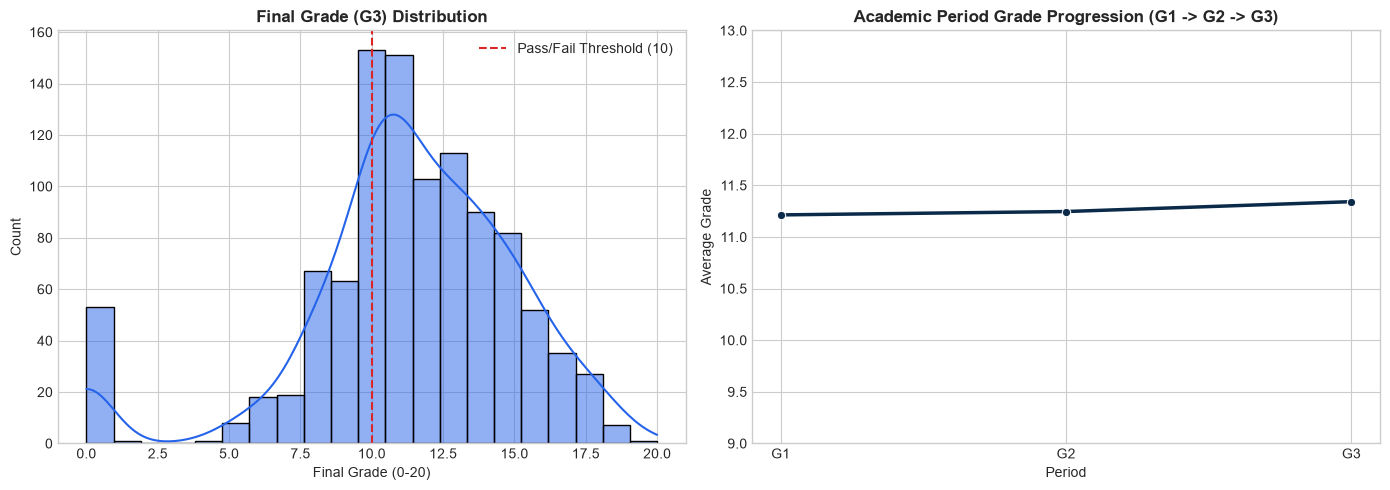

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# G3 Distribution
sns.histplot(df['G3'], bins=21, kde=True, ax=axes[0], color='#2563EB')
axes[0].set_title('Final Grade (G3) Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Final Grade (0-20)')
axes[0].axvline(10, color='#DC2626', linestyle='--', label='Pass/Fail Threshold (10)')
axes[0].legend()

# Grade Progression
prog_df = df[['G1', 'G2', 'G3']].mean().reset_index()
prog_df.columns = ['Period', 'Average Grade']
sns.lineplot(data=prog_df, x='Period', y='Average Grade', marker='o', ax=axes[1], color='#0B2A4A', linewidth=2.5)
axes[1].set_title('Academic Period Grade Progression (G1 -> G2 -> G3)', fontsize=12, fontweight='bold')
axes[1].set_ylim(9, 13)

plt.tight_layout()
plt.show()

### 3. Correlation Matrix of Key Behavioral and Academic Drivers

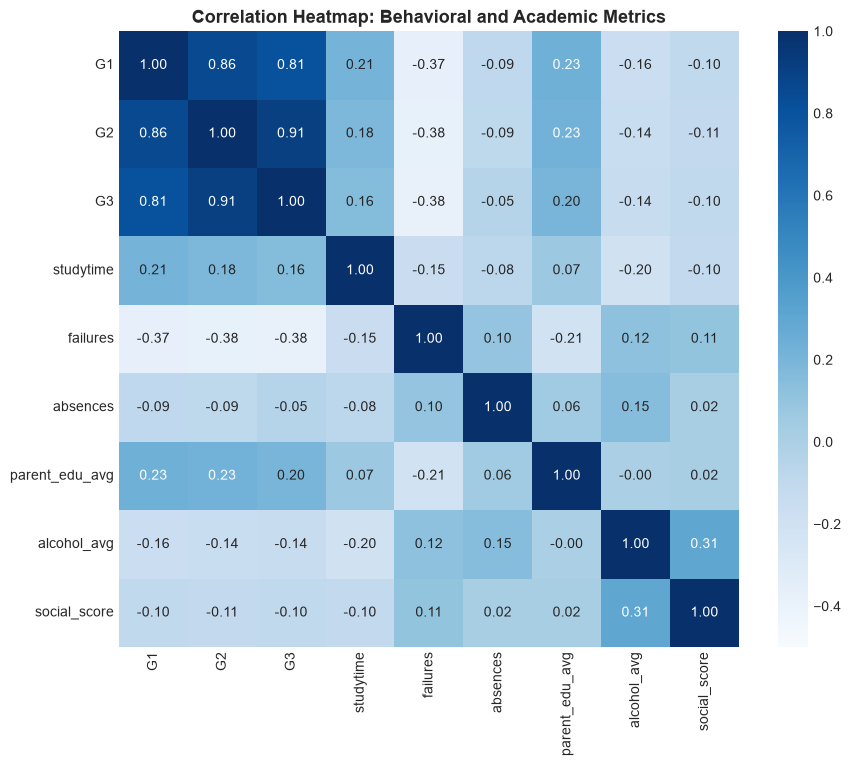

In [4]:
corr_features = ['G1', 'G2', 'G3', 'studytime', 'failures', 'absences', 'parent_edu_avg', 'alcohol_avg', 'social_score']
corr_matrix = df[corr_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.2f', vmin=-0.5, vmax=1.0)
plt.title('Correlation Heatmap: Behavioral and Academic Metrics', fontsize=13, fontweight='bold')
plt.show()

### 4. Key Takeaways & G1/G2 Dominance
1. **Mid-Term Dominance**: Past academic performance ($G1$ and $G2$) displays massive positive correlation ($r > 0.85$) with final grade $G3$.
2. **Early Warning Drivers**: In the absence of mid-term exam marks, primary predictors are **past failures** ($r = -0.38$), **study time** ($r = +0.16$), and **parental educational support** ($r = +0.18$).
3. **Modeling Strategy**:
   - NextGrade AI employs an **Early Warning Mode** (excluding $G1$, $G2$, and grade trend) to diagnose struggling students before initial exams occur.
   - A **Mid-Term Mode** provides high-precision fine-grained prediction ($R^2 > 0.83$) once first-term grades are registered.